# Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.bibs import aps
from libs.inference import categorical
from libs.inference import numeric
from libs import tools_comparison 

Total combinations of features: 1023


# Setup

In [3]:
VERSION = 3
BEST_CH_REG = 2
ROOT_DIR = f'../../results/v{VERSION}/'

FN_PY_INF = f'{ROOT_DIR}/gender/predictions_py/uniqueChineseAllGivenNames_PYgender_reg_mean_894_class_mean_607_1.csv'
FN_CH_GT = f'../../data/v{VERSION}/annotations/gender/ground_truth.csv'
FN_CH_GT_METADATA = f"{ROOT_DIR}/gender/predictions_ch/comparison/rs{BEST_CH_REG}/regression/_mean/ground_truth_MLsampled.csv"

PLOT_DIR = f'{ROOT_DIR}/gender/predictions_py/plots'

ios.validate_path(PLOT_DIR)

In [4]:
vis.sns_paper_style()

# Data

## Ours

In [5]:
df_py = ios.load_csv(FN_PY_INF, dtype={'givenname': str, 'py_givenname': str}, keep_default_na=False, low_memory=False)
df_py.rename(columns={'givenname': 'ch_givenname', 'english_one':'py_givenname', 'pred':'ch_pred', 'pred_label':'ch_pred_label'}, inplace=True)
df_py.rename(columns={c:f"py_{c}" for c in df_py.columns if c.startswith('gender_')}, inplace=True)
df_py.loc[:, 'py_gender_mv'] = df_py.apply(lambda row: categorical.infer_gender_by_supermajority(row['male_label_count'], row['female_label_count'], row['neutral_label_count']), axis=1)
df_py.replace({'py_gender_avg_CNKI': '', 'py_gender_weighted_pop_CNKI': ''}, categorical.np.nan, inplace=True)
df_py.py_gender_avg_CNKI = df_py.py_gender_avg_CNKI.astype(float)
df_py.py_gender_weighted_pop_CNKI = df_py.py_gender_weighted_pop_CNKI.astype(float)
df_py.shape


(46144, 19)

In [6]:
df_py.ch_givenname.nunique(), df_py.py_givenname.nunique()

(46144, 18740)

In [7]:
df_py.sample(5)

,ch_givenname,ch_pred,ch_pred_label,pop_CNKI,pop_NU,NLen,py_givenname,unique_name_count,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,py_gender_mv
33215,海婧,0.746649,female,1,3592.353968,2,haijing,5,0.670560,0.668509,0.635204,0.635204,1,4,0,14,23976.211724,海京#海婧#海晶#海菁#海静,female
671,匹,0.347726,male,0,0.000001,1,pi,46,0.317609,0.317673,0.348261,0.317609,45,0,1,1,99.405556,䴙#丕#仳#伾#僻#劈#匹#吡#啤#噼#嚭#圮#坯#埤#媲#屁#批#披#枇#毗#淠#澼#狉#...,male
33410,涌萍,0.619449,female,1,579.764418,2,yongping,3,0.290674,0.316190,0.566457,0.566457,1,2,0,28,15726.031708,咏萍#永平#涌萍,female
31909,永朋,0.156623,male,1,3999.368510,2,yongpeng,3,0.166290,0.164574,0.163960,0.163960,3,0,0,7,13337.706533,永朋#永蓬#永鹏,male
37341,程奇,0.154177,male,2,1286.656427,2,chengqi,2,0.151337,0.149292,0.149917,0.149917,2,0,0,3,3015.871137,承启#程奇,male


In [8]:
cols_py = ['ch_givenname','py_givenname','ch_pred', 'py_gender_weighted_pop_CNKI', 'py_gender_weighted_pop_NU', 'py_gender_avg_all', 'py_gender_avg_CNKI', 'ch_pred_label', 'py_gender_mv']
df_py[cols_py].head(1)

,ch_givenname,py_givenname,ch_pred,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,ch_pred_label,py_gender_mv
0,㑇,zhou,0.347726,0.281119,0.279068,0.333601,0.280243,male,male


# Regression

In [9]:
PINYIN_AGG_LABELS = {'py_gender_avg_all': 'Mean CNKI+', 
                     'py_gender_weighted_pop_NU': 'Weighted pop.', 
                     'py_gender_avg_CNKI': 'Mean CNKI', 
                     'py_gender_weighted_pop_CNKI': 'Weighted CNKI'}

PINYIN_AGG_LABELS_ORDER = ['py_gender_avg_CNKI', 'py_gender_avg_all', 'py_gender_weighted_pop_CNKI', 'py_gender_weighted_pop_NU']

AMBIGUITY_LABELS = [
        '<0.1',
        '0.1',
        '0.2',
        '0.3',
        '0.4',
        '0.5',
        r'$\geq$ 0.6'
    ]

#### All names

In [10]:
df_py_summary = numeric.get_py_summary(df_py, PINYIN_AGG_LABELS_ORDER, AMBIGUITY_LABELS)

cmap = vis.plt.get_cmap("RdYlGn_r")
colors = [vis.mcolors.to_hex(cmap(x)) for x in vis.np.linspace(0, 1, len(AMBIGUITY_LABELS))]
colors[3] = "#efee81"
df_py_summary.loc[:, 'ambiguity_color'] = df_py_summary['ambiguity_class'].map({'A': colors[0], 'B': colors[1], 'C': colors[2], 'D': colors[3], 'E': colors[4], 'F': colors[5], 'G': colors[6]})

df_py_summary.head(2)


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,py_givenname,ch_n,ch_pred_all,ch_pred_mean,ch_pred_std,ch_pred_min,ch_pred_max,ch_pred_delta,ch_pred_q10,ch_pred_q25,...,py_gender_avg_CNKI_rmse,py_gender_avg_all,py_gender_avg_all_rmse,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_CNKI_rmse,py_gender_weighted_pop_NU,py_gender_weighted_pop_NU_rmse,ambiguity_class,ambiguity_label,ambiguity_color
0,a,4,"[0.5241225453149279, 0.3477259314728446, 0.347...",0.441625,0.108824,0.347726,0.546926,0.1992,0.347726,0.347726,...,NaN,0.441625,9.424474e-02,NaN,NaN,0.546655,1.411146e-01,B,0.1,#4bb05c
1,acan,1,[0.2608237323885916],0.260824,NaN,0.260824,0.260824,0.0000,0.260824,0.260824,...,2.676114e-07,0.260824,2.676114e-07,0.260824,2.676114e-07,0.260824,2.676114e-07,A,<0.1,#006837


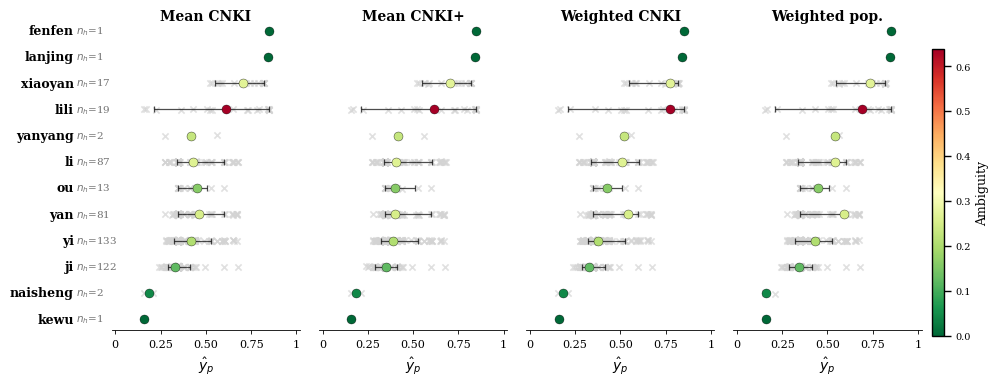

../../results/v3//gender/predictions_py/plots/sample_4x3_detailed.pdf


In [11]:
n_per_group = 4
fn = ios.path_join(PLOT_DIR, f'sample_{n_per_group}x3_detailed.pdf')
vis.plot_py_ch_percentiles(df_py_summary, PINYIN_AGG_LABELS_ORDER, PINYIN_AGG_LABELS, n_per_group=n_per_group, fn=fn)
print(fn)

========== py_gender_avg_all ==========
<0.1 (24927, 21)
0.1 (5623, 21)
0.2 (5405, 21)
0.3 (3944, 21)
0.4 (2947, 21)
0.5 (2473, 21)
$\geq$ 0.6 (825, 21)


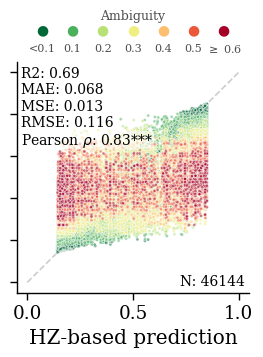

../../results/v3//gender/predictions_py/plots/py_gender_avg_all_vs_ch_gender.pdf
========== py_gender_weighted_pop_NU ==========
<0.1 (24927, 21)
0.1 (5623, 21)
0.2 (5405, 21)
0.3 (3944, 21)
0.4 (2947, 21)
0.5 (2473, 21)
$\geq$ 0.6 (825, 21)


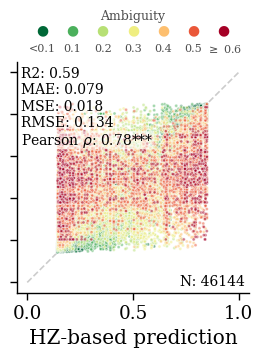

../../results/v3//gender/predictions_py/plots/py_gender_weighted_pop_NU_vs_ch_gender.pdf
========== py_gender_avg_CNKI ==========
<0.1 (24340, 21)
0.1 (5540, 21)
0.2 (5386, 21)
0.3 (3944, 21)
0.4 (2947, 21)
0.5 (2473, 21)
$\geq$ 0.6 (825, 21)


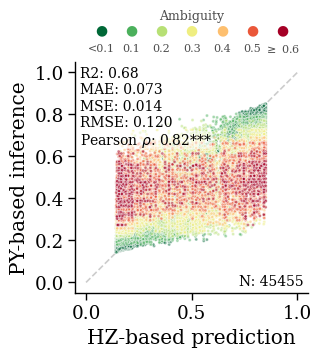

../../results/v3//gender/predictions_py/plots/py_gender_avg_CNKI_vs_ch_gender.pdf
========== py_gender_weighted_pop_CNKI ==========
<0.1 (24340, 21)
0.1 (5540, 21)
0.2 (5386, 21)
0.3 (3944, 21)
0.4 (2947, 21)
0.5 (2473, 21)
$\geq$ 0.6 (825, 21)


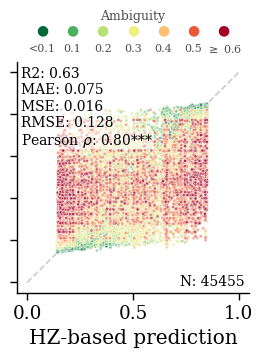

../../results/v3//gender/predictions_py/plots/py_gender_weighted_pop_CNKI_vs_ch_gender.pdf


In [12]:
## Regression
rmse_pred_py_test = None
include_aps = False

col_fixed = 'ch_pred'
for col, label in PINYIN_AGG_LABELS.items():

    print(f"========== {col} ==========")
    df = df_py.dropna(subset=[col]).drop_duplicates(subset=['py_givenname', 'ch_givenname'])
    df[[col, col_fixed]] = df[[col, col_fixed]].astype(float)

    df = df.merge(df_py_summary[['py_givenname', 'ambiguity_color', 'ambiguity_label']], on='py_givenname', how='left')
    
    mae_pred, mse_pred, rmse_pred, r2_pred, pearsonr = numeric.get_performance(df, col_fixed, col)
    performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred, 'pearsonr': pearsonr[0], 'pvalue': numeric.pval_to_stars(pearsonr[1])}

    postfix = '_with_aps' if include_aps else ''
    fn = ios.path_join(PLOT_DIR, f'{col}_vs_ch_gender{postfix}.pdf')
        
    _, ax = vis.plot_regression_performance(df, 
                                            col_x=col_fixed, 
                                            xlabel="HZ-based prediction",

                                            col_y=col, 
                                            ylabel="PY-based inference" if col == 'py_gender_avg_CNKI' else None,
                                            
                                            metrics = performance_py,
                                            figsize=(3, 3), 
                                            title=None,
                                            markersize=5,
                                            markeralpha=0.5,
                                            markercolor=None,

                                            color_col='ambiguity_color',
                                            label_col='ambiguity_label',
                                            label_order=AMBIGUITY_LABELS,
                                            show_yticklabels = PINYIN_AGG_LABELS_ORDER.index(col) == 0,

                                            
                                            fn=fn,
                                            datalabel=None
                                            )
        
    vis.plt.show()
    vis.plt.close()
    print(fn)


#### Ground-truth (held-out)

Loaded 166 Chinese predictions.
../../results/v3//gender/predictions_py/plots/ch_true_vs_py_reg_all.pdf
Plotting py_gender_avg_CNKI vs. ngender_mean...
Plotting py_gender_avg_all vs. ngender_mean...
Plotting py_gender_weighted_pop_CNKI vs. ngender_mean...
Plotting py_gender_weighted_pop_NU vs. ngender_mean...


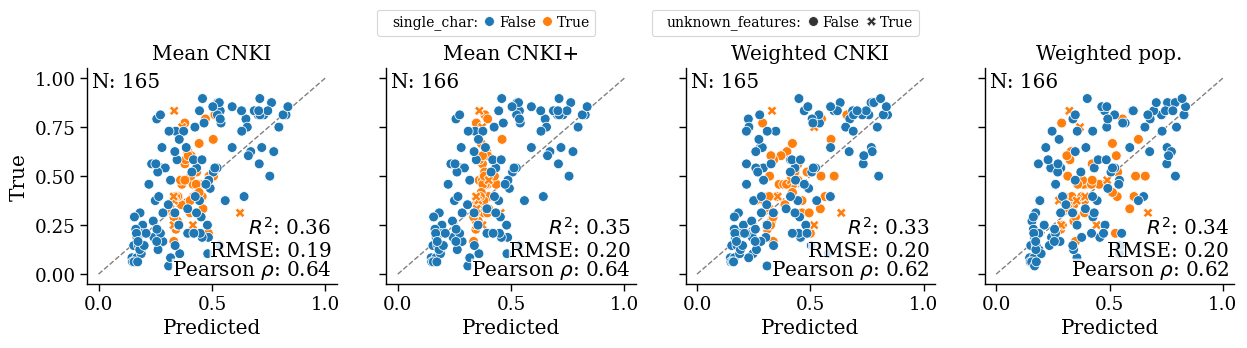

../../results/v3//gender/predictions_py/plots/ch_true_vs_py_reg_test.pdf
Plotting py_gender_avg_CNKI vs. ngender_mean...
Plotting py_gender_avg_all vs. ngender_mean...
Plotting py_gender_weighted_pop_CNKI vs. ngender_mean...
Plotting py_gender_weighted_pop_NU vs. ngender_mean...


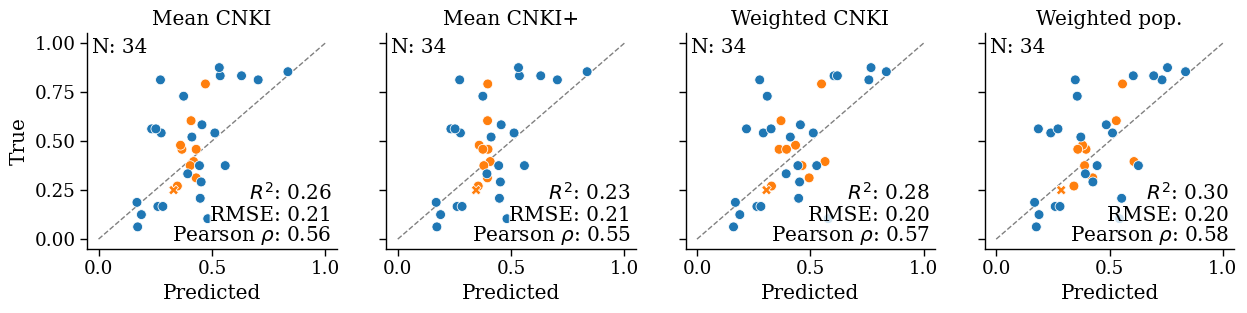

In [13]:
# Performance (GT vs. pred)
df_ch_gt_meta = ios.load_csv(FN_CH_GT_METADATA, dtype={'givenname': str}, keep_default_na=True, index_col=0)
unknown_feature_col = f'{categorical.UNKNOWN}_features'
df_ch_gt_meta.loc[:,unknown_feature_col] = df_ch_gt_meta.apply(lambda row: not ios.pd.notna(row['ngender_r']) and not ios.pd.notna(row['ngender_n']), axis=1)
print(f"Loaded {df_ch_gt_meta.shape[0]} Chinese predictions.")

df_py_comparison = df_py[['ch_givenname','py_givenname','py_gender_avg_all','py_gender_avg_CNKI','py_gender_weighted_pop_NU','py_gender_weighted_pop_CNKI','ch_pred']].set_index('ch_givenname').copy()
df_py_comparison = df_py_comparison.join(df_ch_gt_meta[['ngender_mean','ml_sample','single_char',unknown_feature_col]], how='inner', lsuffix='_py', rsuffix='_gt').reset_index().rename(columns={'index': 'ch_givenname'})

# PLOT
col_true = 'ngender_mean'
# w = 4.1
# h = 2.5
width = 3.7
height = 2.8
ncols = len(PINYIN_AGG_LABELS_ORDER)

for data_set in ['all', 'test']:

    data_tmp = df_py_comparison.query('ml_sample == @data_set').copy() if data_set != 'all' else df_py_comparison.copy()
    fig, axes = vis.plt.subplots(1, ncols, figsize=(width*ncols, height), sharex=True, sharey=True)

    fn = ios.path_join(PLOT_DIR, f'ch_true_vs_py_reg_{data_set}.pdf')
    print(fn)
    
    for col_id, col_pred in enumerate(PINYIN_AGG_LABELS_ORDER):
        
        print(f"Plotting {col_pred} vs. {col_true}...")
        ax = axes[col_id]

        label = PINYIN_AGG_LABELS[col_pred]
        s1 = ios.pd.to_numeric(data_tmp[col_pred], errors="coerce")
        s2 = ios.pd.to_numeric(data_tmp[col_true], errors="coerce")

        tmp = data_tmp.drop(columns=[col_pred, col_true])

        tmp[col_pred] = s1.astype("float64")
        tmp[col_true] = s2.astype("float64")

        tmp = tmp.dropna(subset=[col_pred, col_true])

        mae_pred, mse_pred, rmse_pred, r2_pred, pearsonr = numeric.get_performance(tmp, col_true, col_pred)
        performance_py = {'mae': mae_pred, 
                        'mse': mse_pred, 
                        'rmse': rmse_pred, 
                        'r2': r2_pred, 
                        'pearsonr': pearsonr[0], 
                        'pvalue': numeric.pval_to_stars(pearsonr[1])}
        
        vis.plot_scatter(tmp, 
                        
                        x=col_pred,  
                        xlabel="Predicted",

                        y=col_true, 
                        ylabel='True' if col_id==0 else None, 
                        
                        true_var = col_true,

                        markersize=50,
                        title=PINYIN_AGG_LABELS.get(col_pred, ''),  
                        hue='single_char', 
                        hue_order=[False, True], 
                        
                        style = unknown_feature_col,
                        style_order = [False, True],
                        
                        flatten_legend=True, 
                        
                        palette=None, 
                        corr=True, fit=False, rmse=True, r2=True, diagonal=True,
                        fn=fn,
                        
                        show_legend = col_id == 1 and data_set=='all', # Only show legend for the second plot of Hanzi (since it has more methods)
                        legend_kwargs={'bbox_to_anchor': (0.4, 1.12), 'fontsize': 10, 'title_fontsize':12},

                        ax = ax,
                        save_and_close=col_id==ncols-1
                        )

In [14]:
df_py_summary.head(2)

,py_givenname,ch_n,ch_pred_all,ch_pred_mean,ch_pred_std,ch_pred_min,ch_pred_max,ch_pred_delta,ch_pred_q10,ch_pred_q25,...,py_gender_avg_CNKI_rmse,py_gender_avg_all,py_gender_avg_all_rmse,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_CNKI_rmse,py_gender_weighted_pop_NU,py_gender_weighted_pop_NU_rmse,ambiguity_class,ambiguity_label,ambiguity_color
0,a,4,"[0.5241225453149279, 0.3477259314728446, 0.347...",0.441625,0.108824,0.347726,0.546926,0.1992,0.347726,0.347726,...,NaN,0.441625,9.424474e-02,NaN,NaN,0.546655,1.411146e-01,B,0.1,#4bb05c
1,acan,1,[0.2608237323885916],0.260824,NaN,0.260824,0.260824,0.0000,0.260824,0.260824,...,2.676114e-07,0.260824,2.676114e-07,0.260824,2.676114e-07,0.260824,2.676114e-07,A,<0.1,#006837


In [15]:
ml_sample = 'test'
df_summary_test = ios.pd.DataFrame()
for single_char in [True, False]:
    pynames = df_py_comparison.query("ml_sample==@ml_sample and single_char==@single_char").py_givenname.unique()
    tmp = df_py_summary.query("py_givenname in @pynames").set_index('py_givenname')
    tmp_gt = df_py_comparison.query("ml_sample=='test' and single_char==@single_char").groupby('py_givenname').ngender_mean.mean()

    tmp = tmp.join(tmp_gt, how='left')
    tmp.loc[:, 'single_char'] = single_char
    df_summary_test = ios.pd.concat([df_summary_test, tmp], ignore_index=False)


columns =  ['ch_n', 
            'ngender_mean',
            'single_char',
            'ch_pred_min', 'ch_pred_max',
            'ch_pred_std', 'ch_pred_delta',
            'ambiguity_10-90', 
            'py_gender_avg_CNKI',
            'py_gender_avg_all', 
            'py_gender_weighted_pop_CNKI',
            'py_gender_weighted_pop_NU',
       ]
df_summary_test = df_summary_test[columns]
print(df_summary_test.to_latex(float_format="%.2f"))


\begin{tabular}{lrrrrrrrrrrrr}
\toprule
 & ch_n & ngender_mean & single_char & ch_pred_min & ch_pred_max & ch_pred_std & ch_pred_delta & ambiguity_10-90 & py_gender_avg_CNKI & py_gender_avg_all & py_gender_weighted_pop_CNKI & py_gender_weighted_pop_NU \\
py_givenname &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
fang & 19 & 0.40 & True & 0.28 & 0.65 & 0.11 & 0.37 & 0.21 & 0.42 & 0.41 & 0.56 & 0.61 \\
jie & 52 & 0.46 & True & 0.27 & 0.67 & 0.09 & 0.40 & 0.23 & 0.43 & 0.38 & 0.40 & 0.36 \\
jin & 43 & 0.46 & True & 0.26 & 0.62 & 0.10 & 0.36 & 0.27 & 0.37 & 0.40 & 0.36 & 0.40 \\
jun & 22 & 0.27 & True & 0.25 & 0.60 & 0.09 & 0.35 & 0.22 & 0.35 & 0.36 & 0.33 & 0.34 \\
meng & 25 & 0.79 & True & 0.28 & 0.62 & 0.10 & 0.34 & 0.25 & 0.47 & 0.40 & 0.55 & 0.56 \\
qi & 84 & 0.48 & True & 0.24 & 0.64 & 0.08 & 0.40 & 0.22 & 0.36 & 0.36 & 0.43 & 0.38 \\
shen & 35 & 0.25 & True & 0.28 & 0.54 & 0.06 & 0.26 & 0.11 & 0.33 & 0.35 & 0.31 & 0.29 \\
xi & 101 & 0.38 & True & 0.25 & 0.67 & 0.08 & 0.42 & 0.18 &

# Classification

## Ground-truth (held-out)

In [16]:
df_ch_gt_meta.shape

(166, 13)

In [17]:
df_py_gt = df_py.copy()
df_py_gt.loc[:,'ml_sample'] = df_py_gt.apply(lambda row: 'test' if row['ch_givenname'] in df_ch_gt_meta.query("ml_sample=='test'").index else 'train' if row['ch_givenname'] in df_ch_gt_meta.query("ml_sample=='train'").index else vis.np.nan,  axis=1)

../../results/v3//gender/predictions_py/plots/py_gender_label_cm_all.pdf


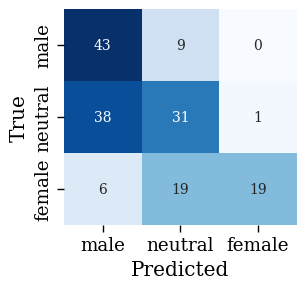

../../results/v3//gender/predictions_py/plots/py_gender_label_cm_testset.pdf


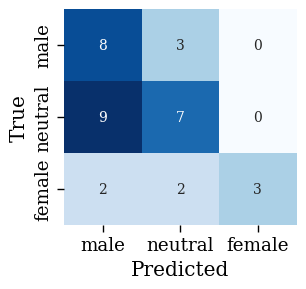

In [18]:
# confusion

labels = categorical.GENDER_LABELS_3
normalize = None
figure_width = 3.0
figure_height = 2.8
cbar = False

# ALL SAMPLES
fig, ax = vis.plt.subplots(1, 1, figsize=(figure_width, figure_height))
fn = f'{PLOT_DIR}/py_gender_label_cm_all.pdf'
print(fn)
cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_py_gt.query("not ml_sample.isna()"), col_true='ch_pred_label', col_pred='py_gender_mv', labels=labels, normalize=normalize)
vis.plot_confusion_matrix(cm, labels, None, 
                                cbar=cbar, 
                                fn = fn,
                                ax=ax,
                                finalize=True)

# TEST
fig, ax = vis.plt.subplots(1, 1, figsize=(figure_width, figure_height))
fn = f'{PLOT_DIR}/py_gender_label_cm_testset.pdf'
print(fn)
cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_py_gt.query("ml_sample == 'test'"), col_true='ch_pred_label', col_pred='py_gender_mv', labels=labels, normalize=normalize)
vis.plot_confusion_matrix(cm, labels, None, 
                          cbar=cbar, 
                          fn = fn,
                          ax=ax,
                          finalize=True)


../../results/v3//gender/predictions_py/plots/py_gender_label_rocauc_all.pdf
../../results/v3//gender/predictions_py/plots/py_gender_label_rocauc_testset.pdf


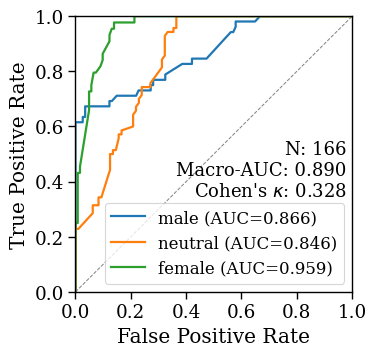

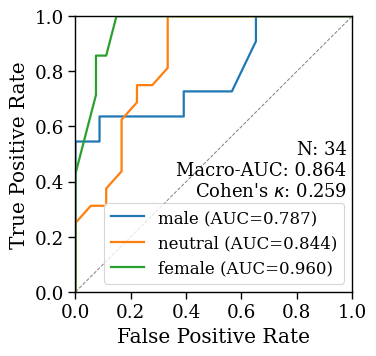

In [19]:
df_py_gt['total_count'] = (
    df_py_gt['male_label_count']
    + df_py_gt['female_label_count']
    + df_py_gt['neutral_label_count']
)

df_py_gt['male_label_proportion'] = (
    df_py_gt['male_label_count']
    / df_py_gt['total_count']
)

df_py_gt['neutral_label_proportion'] = (
    df_py_gt['neutral_label_count']
    / df_py_gt['total_count']
)

df_py_gt['female_label_proportion'] = (
    df_py_gt['female_label_count']
    / df_py_gt['total_count']
)

score_cols = {
    "male": "male_label_proportion",
    "neutral": "neutral_label_proportion",
    "female": "female_label_proportion",
}

figure_width = 4.0
figure_height = 3.8

# ALL
fn = f'{PLOT_DIR}/py_gender_label_rocauc_all.pdf'
print(fn)
fig, ax = vis.plot_multiclass_roc(
    df_py_gt.query("not ml_sample.isna()"),
    true_col="ch_pred_label",
    score_cols=score_cols,
    pred_col="py_gender_mv",
    figsize = (figure_width, figure_height),
    fn = fn
)

# TEST
fn = f'{PLOT_DIR}/py_gender_label_rocauc_testset.pdf'
print(fn)
fig, ax = vis.plot_multiclass_roc(
    df_py_gt.query("ml_sample == 'test'"),
    true_col="ch_pred_label",
    score_cols=score_cols,
    pred_col="py_gender_mv",
    figsize = (figure_width, figure_height),
    fn = fn
)

In [20]:
df_py_agg = categorical.aggregate_by_py(df_py_gt)
df_py_agg.head(2)

,py_givenname,n_h,sc,hat_l_h,n_l_h_male,n_l_h_neutral,n_l_h_female,py_gender_mv,entropy,disagreement,ml_sample
0,a,4,True,neutral,2,2,0,neutral,0.63093,0.5,None
1,acan,1,False,male,1,0,0,male,-0.00000,0.0,None


In [21]:
df_summary_test_label = df_py_agg.query("ml_sample == 'test'").sort_values(['sc', 'entropy'], ascending=[False, True]).drop(columns=['hat_l_h','ml_sample']).set_index('py_givenname')
print(df_summary_test_label.to_latex(float_format="%.2f"))

\begin{tabular}{lrrrrrlrr}
\toprule
 & n_h & sc & n_l_h_male & n_l_h_neutral & n_l_h_female & py_gender_mv & entropy & disagreement \\
py_givenname &  &  &  &  &  &  &  &  \\
\midrule
shen & 35 & True & 31 & 4 & 0 & male & 0.32 & 0.11 \\
jun & 22 & True & 18 & 4 & 0 & male & 0.43 & 0.18 \\
qi & 84 & True & 69 & 14 & 1 & male & 0.47 & 0.18 \\
jie & 52 & True & 41 & 8 & 3 & male & 0.58 & 0.21 \\
zhen & 42 & True & 29 & 12 & 1 & male & 0.64 & 0.31 \\
meng & 25 & True & 17 & 7 & 1 & male & 0.68 & 0.32 \\
jin & 43 & True & 26 & 16 & 1 & neutral & 0.69 & 0.63 \\
xuan & 40 & True & 27 & 10 & 3 & male & 0.73 & 0.33 \\
fang & 19 & True & 11 & 6 & 2 & neutral & 0.84 & 0.68 \\
bingchen & 2 & False & 2 & 0 & 0 & male & -0.00 & 0.00 \\
bohua & 2 & False & 2 & 0 & 0 & male & -0.00 & 0.00 \\
haian & 1 & False & 1 & 0 & 0 & male & -0.00 & 0.00 \\
jianju & 1 & False & 1 & 0 & 0 & male & -0.00 & 0.00 \\
nianman & 1 & False & 1 & 0 & 0 & male & -0.00 & 0.00 \\
qingdong & 3 & False & 3 & 0 & 0 & male & -0

In [22]:
df_py_agg['entropy'].corr(df_py_agg['disagreement'], method='spearman')

0.9963005317098954

## Sample (all names)

../../results/v3//gender/predictions_py/plots/py_gender_label_disagreement.pdf


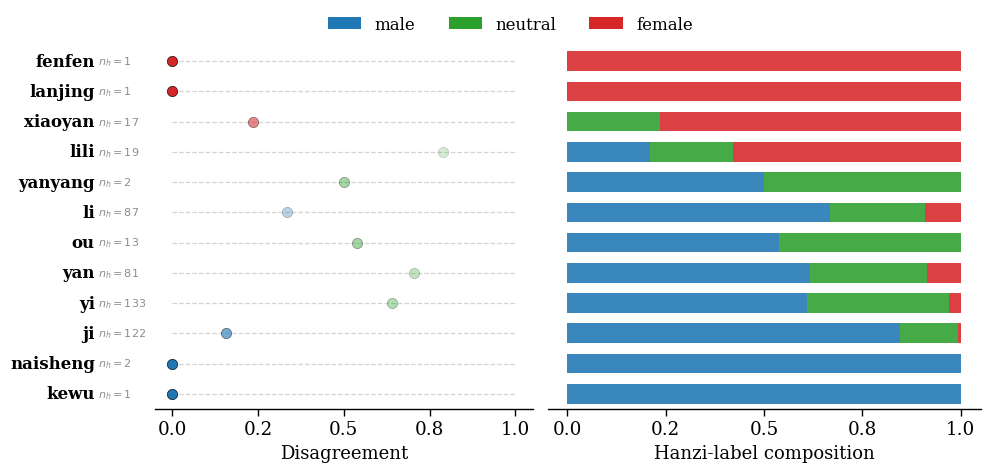

In [23]:
pynames = ['fenfen','lanjing','xiaoyan','lili','yanyang','li','ou','yan','yi','ji','naisheng','kewu']
pynames = pynames[::-1]

fn = f'{PLOT_DIR}/py_gender_label_disagreement.pdf'
print(fn)
vis.plot_py_disagreement(df_py_agg, pynames, categorical.GENDER_LABELS_3, fn)
